# Lab 11: Attention


**Dhiyaa Abdu Madkhali - 2230004228**

### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # inputs are (questions, words)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear the gradients from the previous epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")
print(f"Final loss: {loss.item():.4f}")

Training finished!
Final loss: 0.0967


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

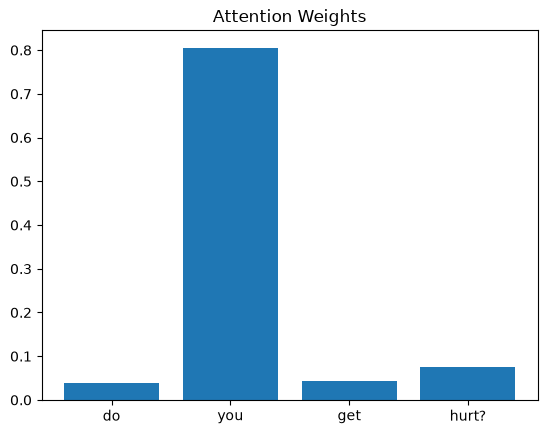

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: How old are you?
Predicted answer: Age doesn't really apply to me.
Highest attention: 'how' (0.311)
All words: how (0.311), old (0.158), are (0.026), you (0.074) 

Question: Who created you?
Predicted answer: People created me.
Highest attention: 'you' (0.479)
All words: who (0.384), created (0.111), you (0.479) 

Question: What is your favorite meal?
Predicted answer: I don't need to eat.
Highest attention: 'meal' (0.923)
All words: what (0.014), is (0.000), your (0.002), favorite (0.060), meal (0.923) 



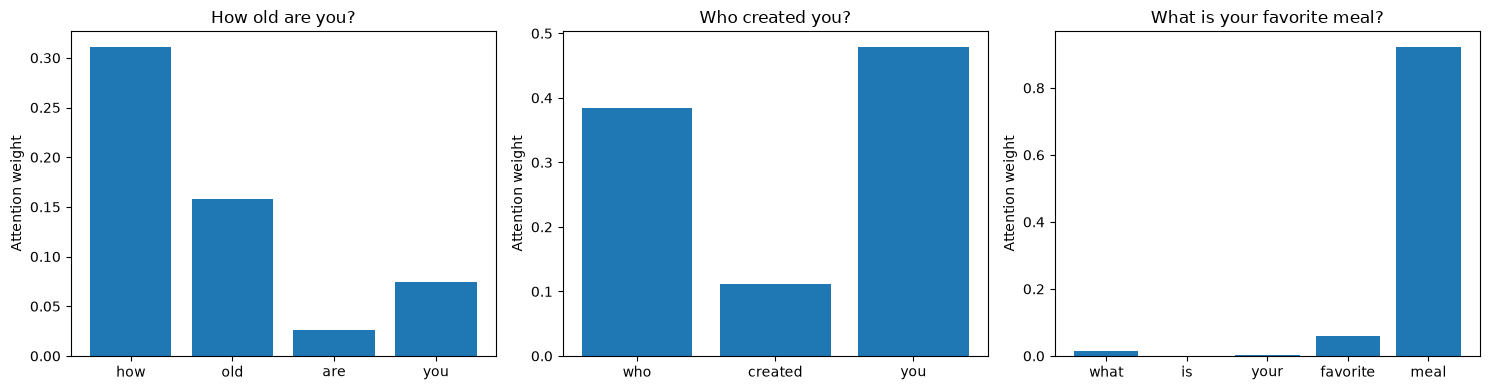

In [7]:
def attention_for(question):
    sequence = tokenizer.texts_to_sequences([question.lower()])[0]
    padded = pad_sequences([sequence], maxlen=X.shape[1], padding="post")
    with torch.no_grad():
        prediction, weights = model(torch.tensor(padded, dtype=torch.long))
    words = [tokenizer.index_word[i] for i in sequence]
    answer = df.loc[df["answer_id"] == prediction.argmax(1).item(), "answer"].iloc[0]
    return words, weights[0, :len(words)].tolist(), answer

task1_questions = ["How old are you?", "Who created you?", "What is your favorite meal?"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, question in zip(axes, task1_questions):
    words, weights, answer = attention_for(question)
    ax.bar(words, weights)
    ax.set_title(question)
    ax.set_ylabel("Attention weight")

    top_word = words[weights.index(max(weights))]
    print(f"Question: {question}")
    print(f"Predicted answer: {answer}")
    print(f"Highest attention: '{top_word}' ({max(weights):.3f})")
    print("All words:", ", ".join(f"{w} ({a:.3f})" for w, a in zip(words, weights)), "\n")

plt.tight_layout()
plt.show()

**Answer**

Mostly yes. In *What is your favorite meal?* almost all of the attention (0.92) is on **meal**, which is the word that tells the model the question is about food. In *How old are you?* the top word is **how** (0.31) and **old** is second (0.16). Together they form "how old", which is what separates an age question from the other groups.

In *Who created you?* the top word is **you** (0.48), followed by **who** (0.38), while **created** only gets 0.11 even though a person would see it as the key word. Attention is learned only to help predict the answer group, so the model focuses on whatever words were useful clues in the training data, and *who* appears in many of the "who made you" questions (*Who programmed you?*, *Who built you?*, *Who is your designer?*). All three questions were still matched to the correct answer.

The weights of the real words do not add up to 1 because part of the attention also goes to the padding positions at the end of the sequence.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: Who created you?
Predicted answer: People created me.
Words by attention: you (0.479), who (0.384), created (0.111) 

Question: Which company made you?
Predicted answer: People created me.
Words by attention: company (0.545), made (0.243), you (0.165), which (0.013) 



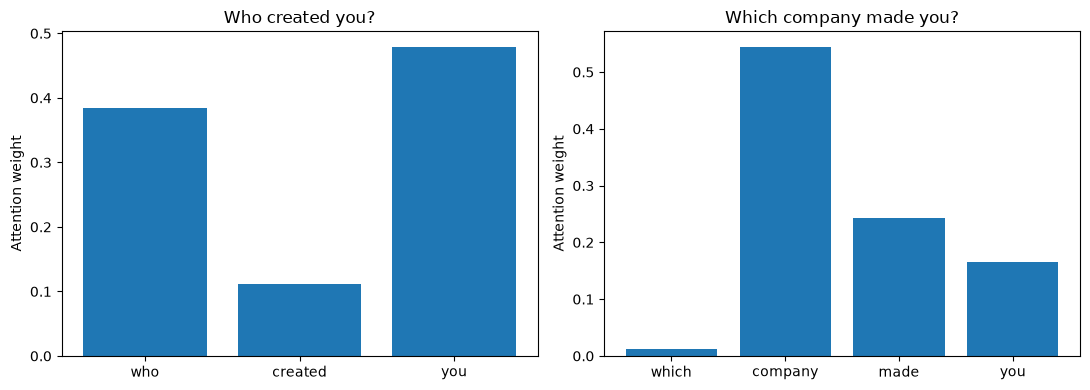

In [8]:
task2_questions = ["Who created you?", "Which company made you?"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, question in zip(axes, task2_questions):
    words, weights, answer = attention_for(question)
    ax.bar(words, weights)
    ax.set_title(question)
    ax.set_ylabel("Attention weight")

    ranked = sorted(zip(words, weights), key=lambda pair: pair[1], reverse=True)
    print(f"Question: {question}")
    print(f"Predicted answer: {answer}")
    print("Words by attention:", ", ".join(f"{w} ({a:.3f})" for w, a in ranked), "\n")

plt.tight_layout()
plt.show()

**Answer**

Both questions mean the same thing, and both were matched to the same answer ("People created me."), but the model focused on different words. In *Who created you?* most of the attention went to **you** and **who**. In *Which company made you?* the top word was **company** (0.55), followed by **made** (0.24), and **which** got almost none.

This suggests that attention does not compare meanings directly. It gives weight to the words that the model learned are good clues for each answer group, and different wordings can reach the same answer through different clue words (*who* in one question, *company* in the other). Because the RNN reads the words in order, the weight of each word also depends on the words that came before it.